
# DSC212 Research Assignment: Modularity on the Karate Club Graph

**Topic:** Recursive spectral modularity partitioning  
**Dataset:** Zachary's Karate Club graph

## 1. Aim

The aim is to detect communities in the Karate Club network using recursive spectral modularity partitioning, visualise the detected communities, calculate network metrics after each accepted split, and discuss how community structure relates to node importance.

## 2. Method

For the undirected graph, let \(A\) be its adjacency matrix, \(k\) its degree vector, and \(m\) its number of edges. The modularity matrix is

\[
B=A-\frac{kk^\top}{2m}.
\]

For a candidate community \(C\), we take the corresponding block \(B^{(C)}\) of the **original global modularity matrix**. We compute its largest eigenvalue and corresponding eigenvector.

- If the largest eigenvalue is nonpositive, we stop splitting that community.
- If it is positive, we divide the nodes according to the signs of the leading eigenvector.
- We repeat this process recursively for the resulting communities.

This follows the method described in the assignment handout and Newman (2006).

## 3. Imports and reproducibility

The implementation uses NumPy, Matplotlib and NetworkX. A fixed spring-layout seed makes the graph drawings reproducible.


In [1]:

import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
import pandas as pd

np.set_printoptions(precision=4, suppress=True)
print("NumPy version:", np.__version__)
print("NetworkX version:", nx.__version__)


NumPy version: 2.3.5
NetworkX version: 3.6.1



## 4. Load and inspect the Karate Club graph

NetworkX provides Zachary's Karate Club graph as a built-in dataset. Each node represents a club member and each edge represents a recorded friendship/interaction.


In [2]:

G = nx.karate_club_graph()
nodes = list(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Number of nodes: {n}")
print(f"Number of edges: {m}")
print("Graph is undirected:", not G.is_directed())


Number of nodes: 34
Number of edges: 78
Graph is undirected: True


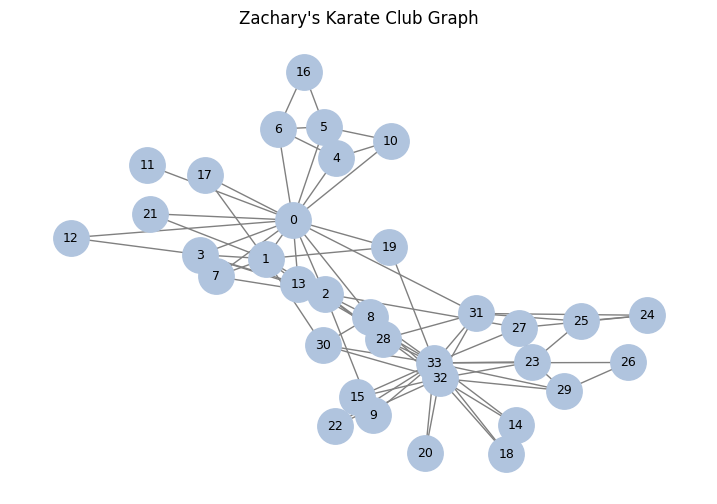

In [3]:

# Draw the original graph. Node labels are the node IDs.
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(9, 6))
nx.draw_networkx(
    G, pos=pos, with_labels=True,
    node_color="lightsteelblue", edge_color="gray",
    node_size=650, font_size=9
)
plt.title("Zachary's Karate Club Graph")
plt.axis("off")
plt.show()



## 5. Construct the modularity matrix

The adjacency matrix is \(A\). The degree of node \(i\) is \(k_i\), and the total degree is \(2m\). We construct

\[
B=A-\frac{kk^\top}{2m}.
\]

The matrix is real and symmetric because the graph is undirected.


In [4]:

A = nx.to_numpy_array(G, nodelist=nodes, dtype=float)
degree = A.sum(axis=1)
B = A - np.outer(degree, degree) / (2 * m)

print("Shape of adjacency matrix:", A.shape)
print("Shape of modularity matrix:", B.shape)
print("Is B symmetric?", np.allclose(B, B.T))
print("Maximum absolute row sum of B:", np.max(np.abs(B.sum(axis=1))))


Shape of adjacency matrix: (34, 34)
Shape of modularity matrix: (34, 34)
Is B symmetric? True
Maximum absolute row sum of B: 94.15384615384616



## 6. Recursive spectral modularity partitioning

For each candidate community, the code extracts the matching rows and columns from the **global** modularity matrix. It then uses `numpy.linalg.eigh`, which is designed for real symmetric matrices.

The leading eigenvector is thresholded at zero to obtain two groups. A split is accepted only when the largest eigenvalue is positive and both resulting groups are nonempty.


In [5]:

def recursive_spectral_partition(B_global, node_list, tolerance=1e-10):
    """Recursively split node groups using the leading eigenpair of B_global.

    Parameters
    ----------
    B_global : numpy.ndarray
        Modularity matrix of the full original graph.
    node_list : list
        Node labels in the same order used to construct B_global.
    tolerance : float
        Numerical tolerance for the eigenvalue stopping test.

    Returns
    -------
    snapshots : list of list
        Each entry is the full partition after one accepted split.
    split_log : list of dict
        Information about each accepted split.
    """
    position = {node: i for i, node in enumerate(node_list)}
    communities = [list(node_list)]
    snapshots = []
    split_log = []

    # Queue entries are community node lists. A community is processed once.
    queue = deque([list(node_list)])

    while queue:
        community = queue.popleft()

        if len(community) < 2:
            continue

        indices = [position[node] for node in community]
        B_C = B_global[np.ix_(indices, indices)]

        eigenvalues, eigenvectors = np.linalg.eigh(B_C)
        leading_value = float(eigenvalues[-1])
        leading_vector = eigenvectors[:, -1]

        if leading_value <= tolerance:
            continue

        group_positive = [
            community[i] for i, value in enumerate(leading_vector) if value > 0
        ]
        group_nonpositive = [
            community[i] for i, value in enumerate(leading_vector) if value <= 0
        ]

        # Do not accept a degenerate split.
        if len(group_positive) == 0 or len(group_nonpositive) == 0:
            continue

        # Replace the current community by its two children.
        communities.remove(community)
        communities.extend([group_positive, group_nonpositive])

        split_log.append({
            "split_number": len(split_log) + 1,
            "parent_size": len(community),
            "largest_eigenvalue": leading_value,
            "group_1_size": len(group_positive),
            "group_2_size": len(group_nonpositive)
        })
        snapshots.append([list(c) for c in communities])

        queue.append(group_positive)
        queue.append(group_nonpositive)

    return snapshots, split_log


snapshots, split_log = recursive_spectral_partition(B, nodes)

print("Number of accepted splits:", len(snapshots))
print("Number of final communities:", len(snapshots[-1]) if snapshots else 1)
print("\nSplit details:")
pd.DataFrame(split_log)


Number of accepted splits: 12
Number of final communities: 13

Split details:


,split_number,parent_size,largest_eigenvalue,group_1_size,group_2_size
0,1,34,17.108349,18,16
1,2,18,7.879863,12,6
2,3,16,9.851071,8,8
3,4,12,3.789452,2,10
4,5,6,4.224803,4,2
5,6,8,2.112386,4,4
6,7,8,5.457362,3,5
7,8,10,1.883391,8,2
8,9,4,0.463469,1,3
9,10,4,1.765911,3,1



## 7. Visualise the graph after every accepted split

Each community receives a different colour. The same spring-layout coordinates are used in every figure so that changes in community membership can be compared fairly.


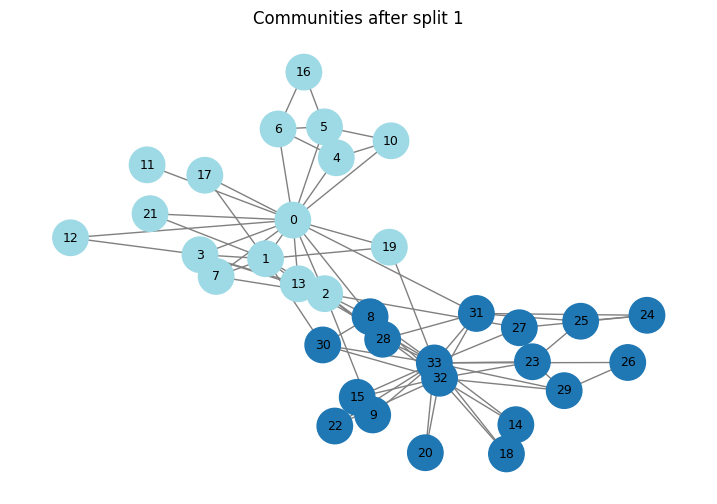

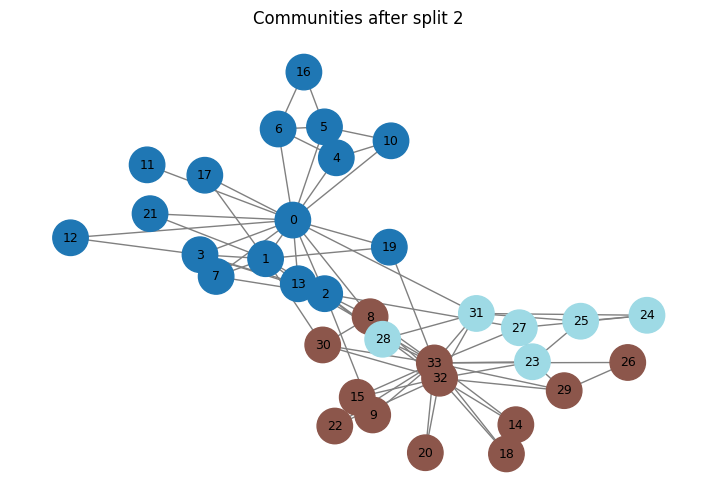

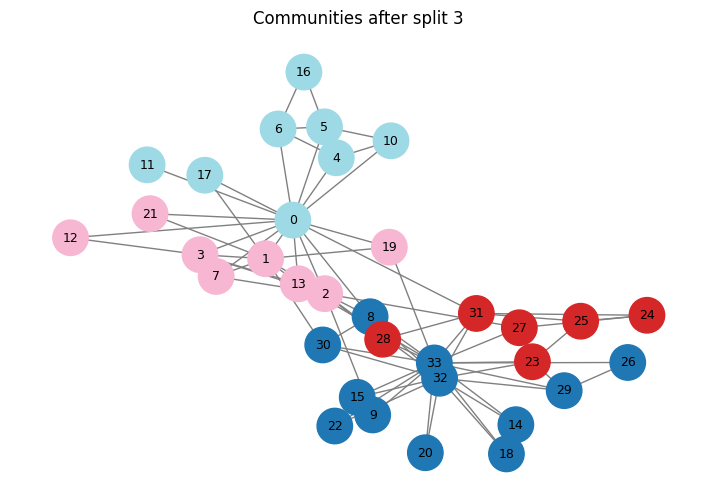

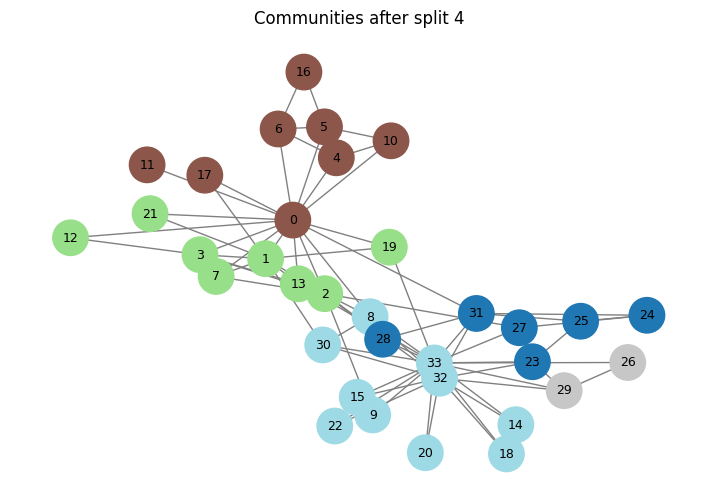

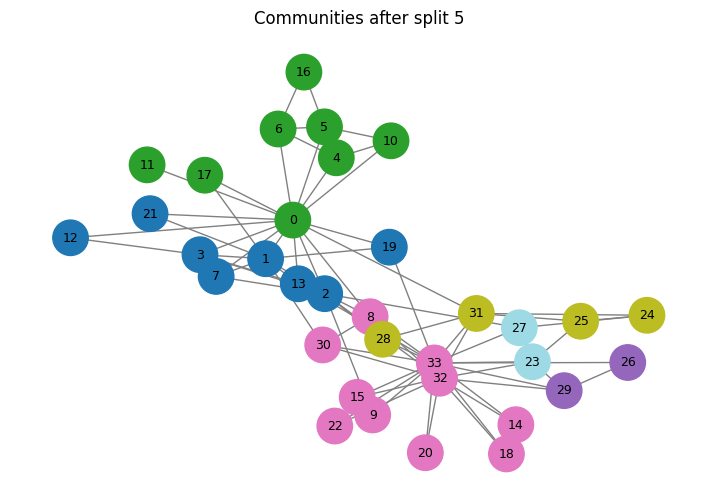

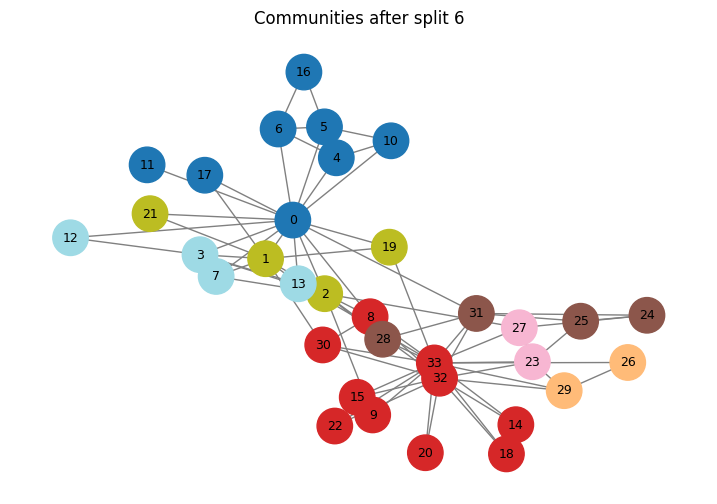

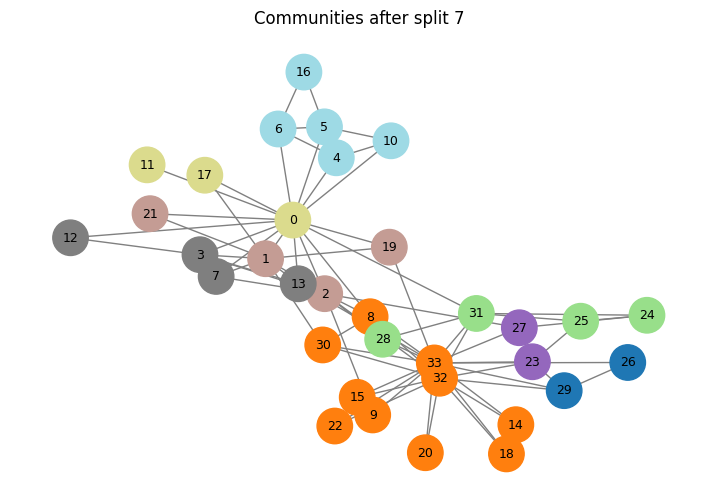

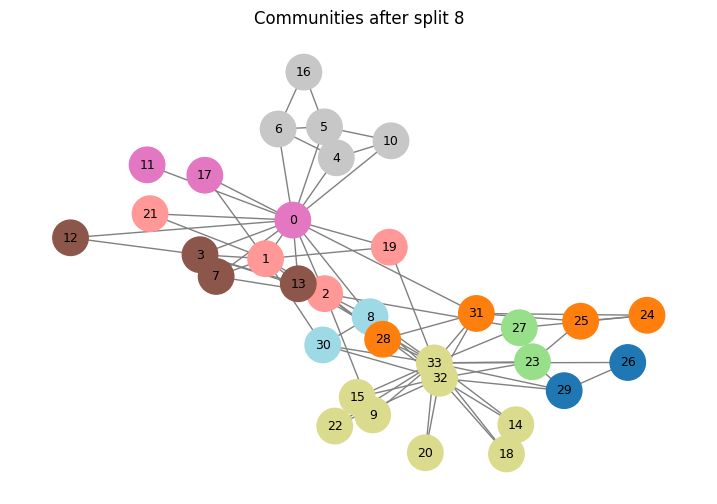

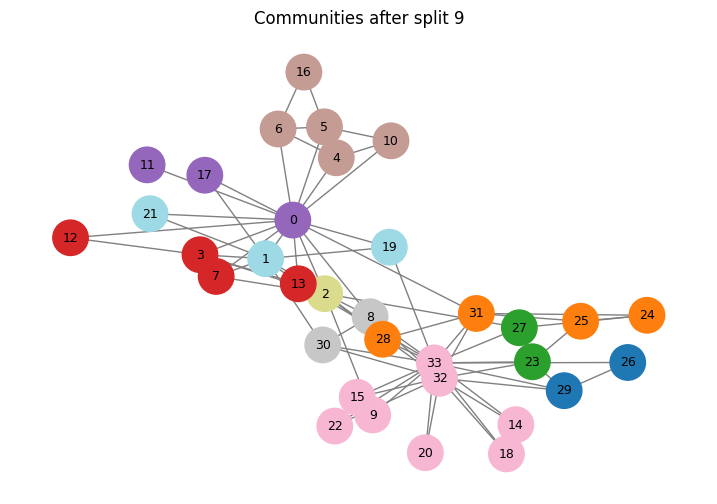

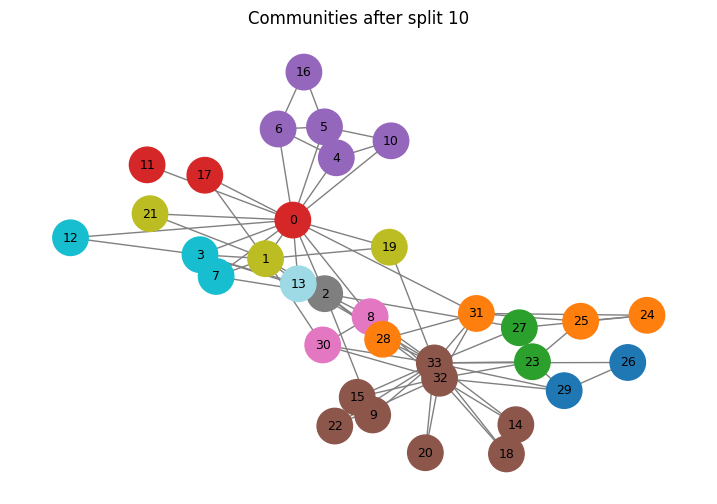

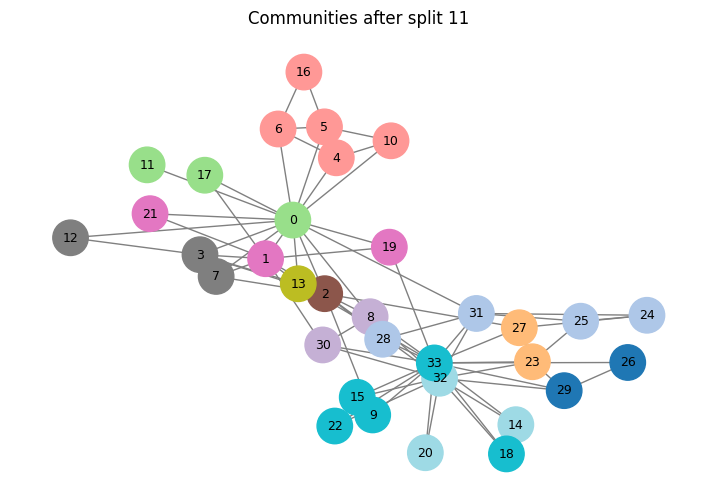

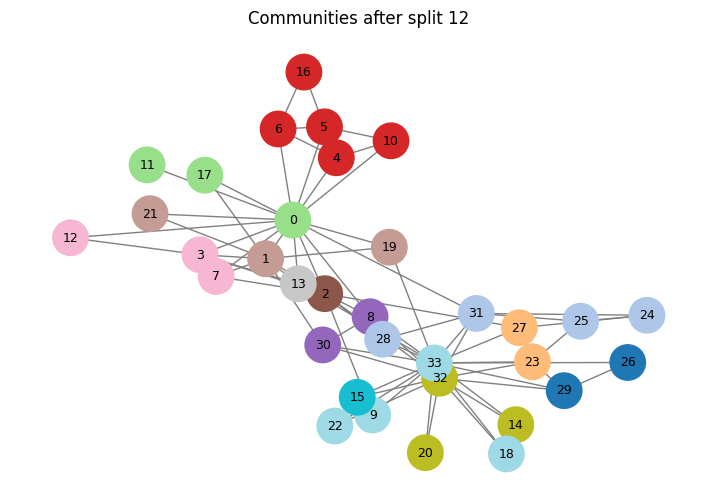

In [6]:

def draw_partition(graph, partition, layout, title):
    """Draw a graph with a separate colour for each community."""
    color_names = plt.cm.tab20(np.linspace(0, 1, max(len(partition), 1)))
    node_to_color = {}
    for community_id, community in enumerate(partition):
        for node in community:
            node_to_color[node] = color_names[community_id]

    node_colors = [node_to_color[node] for node in graph.nodes()]

    plt.figure(figsize=(9, 6))
    nx.draw_networkx(
        graph, pos=layout, with_labels=True,
        node_color=node_colors, edge_color="gray",
        node_size=650, font_size=9
    )
    plt.title(title)
    plt.axis("off")
    plt.show()


for step, partition in enumerate(snapshots, start=1):
    draw_partition(G, partition, pos, f"Communities after split {step}")



## 8. Calculate node metrics after each split

The assignment asks for degree centrality, betweenness centrality, closeness centrality and clustering coefficient after each iteration.

To make the metric evolution informative, the metrics below are calculated **inside each node's current community-induced subgraph**. Thus, as communities become smaller, a node's centrality is measured relative to the members of its current community. This is different from recalculating the metrics on the unchanged full graph, which would give the same values at every iteration.

For every snapshot, each node belongs to exactly one community. The metric values are stored by split number and node ID.


In [7]:

metric_names = [
    "degree_centrality",
    "betweenness_centrality",
    "closeness_centrality",
    "clustering"
]

# Include the original one-community partition as iteration 0.
partitions_by_iteration = [[list(nodes)]] + snapshots
metric_history = {}

for iteration, partition in enumerate(partitions_by_iteration):
    values_for_iteration = {
        node: {metric: np.nan for metric in metric_names}
        for node in nodes
    }

    for community in partition:
        subgraph = G.subgraph(community).copy()

        degree_values = nx.degree_centrality(subgraph)
        betweenness_values = nx.betweenness_centrality(subgraph)
        closeness_values = nx.closeness_centrality(subgraph)
        clustering_values = nx.clustering(subgraph)

        for node in community:
            values_for_iteration[node]["degree_centrality"] = degree_values[node]
            values_for_iteration[node]["betweenness_centrality"] = betweenness_values[node]
            values_for_iteration[node]["closeness_centrality"] = closeness_values[node]
            values_for_iteration[node]["clustering"] = clustering_values[node]

    metric_history[iteration] = values_for_iteration

print("Metric values stored for iterations:", list(metric_history.keys()))


Metric values stored for iterations: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [8]:

# Display the metric values for every node at the final iteration.
final_iteration = max(metric_history)
final_rows = []
for node in nodes:
    row = {"node": node}
    row.update(metric_history[final_iteration][node])
    final_rows.append(row)

final_metrics_df = pd.DataFrame(final_rows).set_index("node")
final_metrics_df.round(4)


,degree_centrality,betweenness_centrality,closeness_centrality,clustering
node,,,,
0,1.0000,1.0000,1.0000,0.0000
1,1.0000,1.0000,1.0000,0.0000
2,1.0000,0.0000,0.0000,0.0000
3,1.0000,1.0000,1.0000,0.0000
4,0.5000,0.0833,0.6667,0.0000
5,0.7500,0.2500,0.8000,0.3333
6,0.7500,0.2500,0.8000,0.3333
7,0.5000,0.0000,0.6667,0.0000
8,1.0000,0.0000,1.0000,0.0000



## 9. Plot metric evolution across iterations

Each line represents one node. The horizontal axis is the iteration number (0 is the original graph before any split). Values are computed within the node's current community at that iteration.


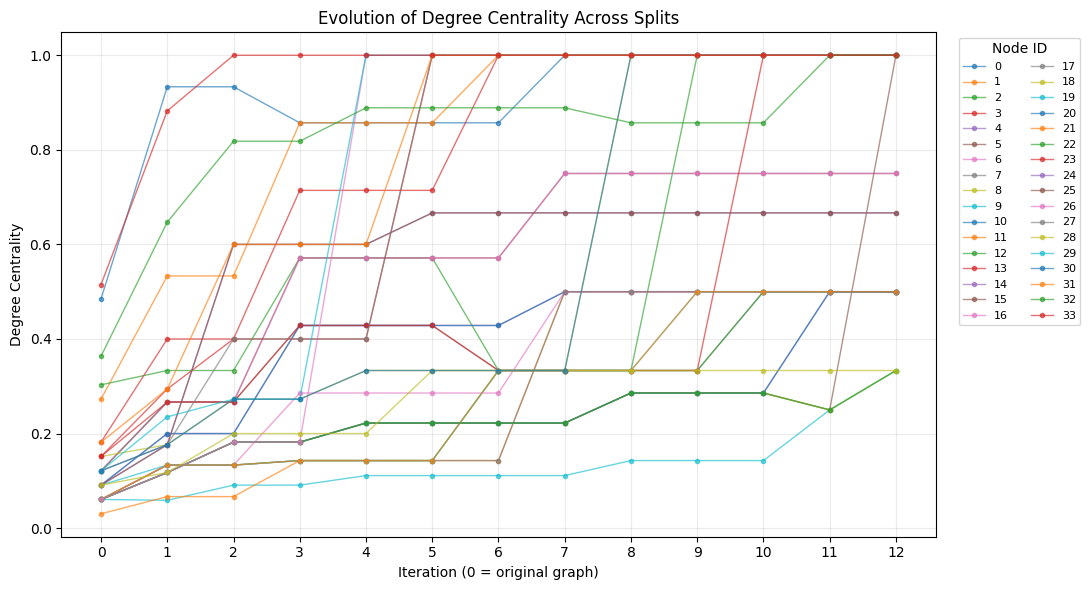

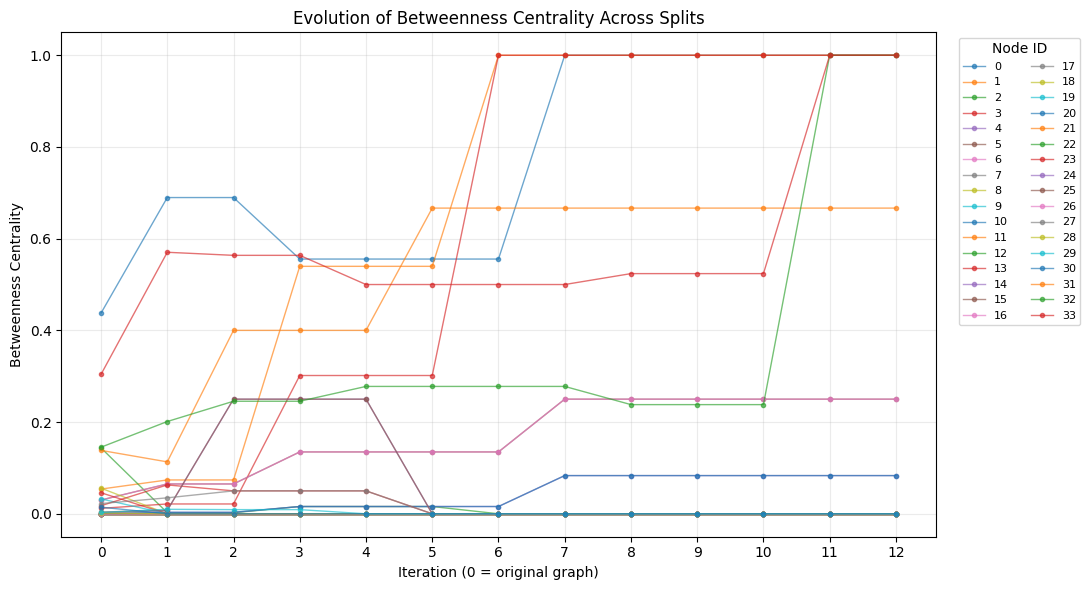

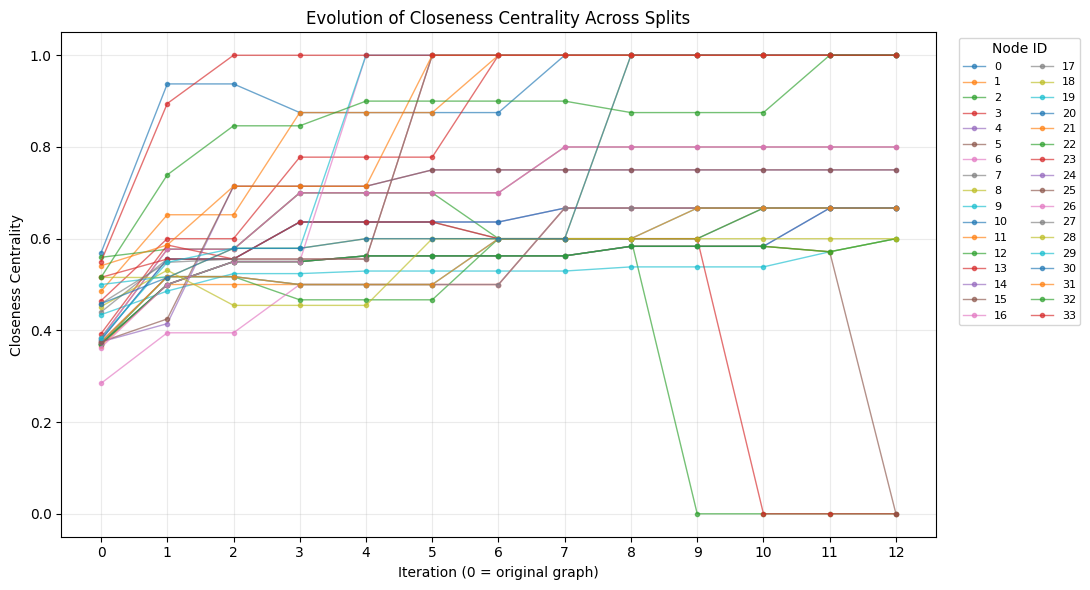

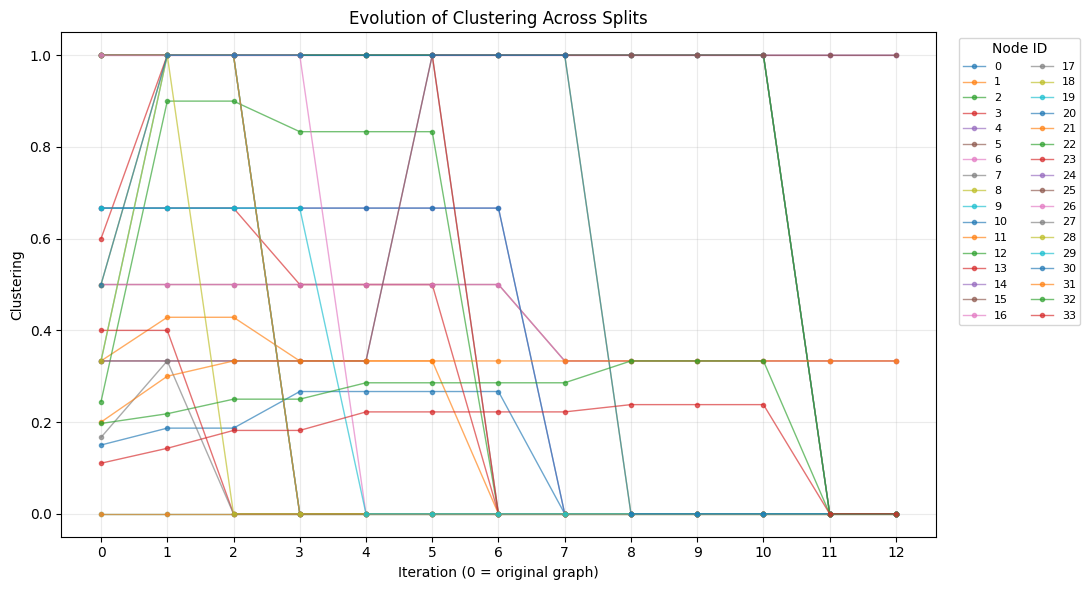

In [9]:

for metric in metric_names:
    plt.figure(figsize=(11, 6))
    for node in nodes:
        y_values = [
            metric_history[iteration][node][metric]
            for iteration in sorted(metric_history)
        ]
        plt.plot(
            sorted(metric_history), y_values,
            marker="o", markersize=3, linewidth=1,
            alpha=0.65, label=str(node)
        )

    plt.xlabel("Iteration (0 = original graph)")
    plt.ylabel(metric.replace("_", " ").title())
    plt.title(f"Evolution of {metric.replace('_', ' ').title()} Across Splits")
    plt.xticks(sorted(metric_history))
    plt.grid(alpha=0.25)
    plt.legend(
        title="Node ID", bbox_to_anchor=(1.02, 1),
        loc="upper left", ncol=2, fontsize=8
    )
    plt.tight_layout()
    plt.show()



## 10. Discussion

The recursive spectral method uses the leading eigenvector of the restricted modularity matrix to identify a direction along which a community can be divided. A positive leading eigenvalue indicates that a split can produce a positive modularity gain under the criterion in the assignment. The process stops for a community when its leading eigenvalue is nonpositive.

Degree centrality identifies nodes with many direct connections. Betweenness centrality identifies nodes that often lie on shortest paths and can therefore act as bridges. Closeness centrality measures how near a node is, on average, to the other nodes in its community. The clustering coefficient measures how interconnected a node's neighbours are.

A node can have high degree but low betweenness if its neighbours are also well connected to one another. Conversely, a node with fewer connections can have high betweenness if it connects otherwise separate parts of the network. When the graph is divided into communities, paths and neighbourhoods are evaluated within smaller induced subgraphs, so the metrics can change. In particular, nodes that connect different communities may lose some of their bridging role when measured only within their own community.

The plots and final metric table should be used to identify the particular node IDs that remain relatively central in this run. The exact values are produced by the code above rather than assumed in advance.


In [10]:

# Identify the five highest-scoring nodes for each metric at the final iteration.
for metric in metric_names:
    print(f"Top nodes by {metric}:")
    display(final_metrics_df[metric].sort_values(ascending=False).head(5).to_frame())


Top nodes by degree_centrality:


,degree_centrality
node,
0,1.0
1,1.0
2,1.0
3,1.0
8,1.0


Top nodes by betweenness_centrality:


,betweenness_centrality
node,
0,1.0
1,1.0
3,1.0
33,1.0
32,1.0


Top nodes by closeness_centrality:


,closeness_centrality
node,
0,1.0
1,1.0
3,1.0
8,1.0
29,1.0


Top nodes by clustering:


,clustering
node,
24,1.000000
16,1.000000
25,1.000000
31,0.333333
6,0.333333



## 11. Conclusion

This assignment implemented recursive spectral modularity partitioning on Zachary's Karate Club graph. The modularity matrix was constructed from the adjacency matrix and degree sequence. Communities were split using the signs of the leading eigenvector whenever the largest eigenvalue of the restricted modularity matrix was positive. The resulting partitions were visualised, and node-level centrality and clustering metrics were tracked across iterations.

## 12. Reference

Newman, M. E. J. (2006). *Modularity and community structure in networks*. Proceedings of the National Academy of Sciences, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103
